In [1]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'

In [3]:
!wget $data

--2026-11-01 10:57:20--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.004s  

2026-11-01 10:57:20 (149 MB/s) - ‘car_fuel_efficiency_2026.csv’ saved [635180/635180]



# Question 1 (model_year)

In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

df = pd.read_csv(data)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

train_dicts = df_train.fillna(0).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

dt = DecisionTreeRegressor(max_depth=1, random_state=1)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



# Question 2 (1.837)

In [28]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import root_mean_squared_error

df = pd.read_csv(data)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

train_dicts = df_train.fillna(0).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

rfr = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rfr.fit(X_train, y_train)

val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

y_pred = rfr.predict(X_val)
rmse = root_mean_squared_error(y_val, y_pred)

print(f"RMSE:{rmse}")

RMSE:1.8336350509302553


# Question 3 (100)

In [33]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import root_mean_squared_error

df = pd.read_csv(data)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

train_dicts = df_train.fillna(0).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

rmses = []
for e in [10, 50, 100, 150]:
    rfr = RandomForestRegressor(n_estimators=e, random_state=1, n_jobs=-1)
    rfr.fit(X_train, y_train)
    
    y_pred = rfr.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred)

    rmses.append((e, round(rmse,3)))

print("RMSEs:", *rmses, sep="\n")

RMSEs:
(10, 1.834)
(50, 1.77)
(100, 1.768)
(150, 1.768)


# Question 4 (10)

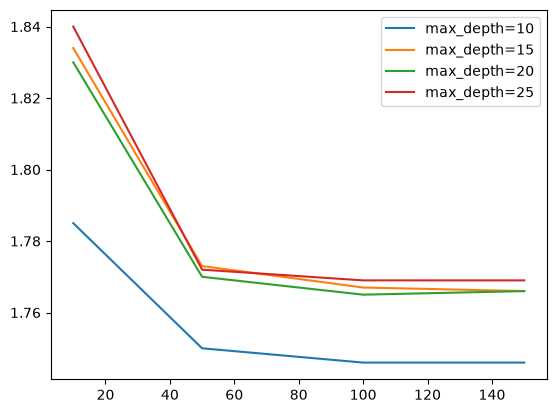

In [36]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import root_mean_squared_error

from matplotlib import pyplot as plt
%matplotlib inline

df = pd.read_csv(data)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

train_dicts = df_train.fillna(0).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

rmses = []
for d in [10, 15, 20, 25]:
    for e in [10, 50, 100, 150]:
        rfr = RandomForestRegressor(n_estimators=e, max_depth = d, random_state=1, n_jobs=-1)
        rfr.fit(X_train, y_train)
        
        y_pred = rfr.predict(X_val)
        rmse = root_mean_squared_error(y_val, y_pred)
    
        rmses.append((d, e, round(rmse,3)))

columns = ['max_depth', 'n_estimators', 'rmse']
df_scores = pd.DataFrame(rmses, columns=columns)

for d in [10, 15, 20, 25]:
    df_subset = df_scores[df_scores.max_depth == d]
    
    plt.plot(df_subset.n_estimators, df_subset.rmse,
             label='max_depth=%d' % d)

plt.legend()
plt.show()

# Question 5 (vehicle_weight)

In [41]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import root_mean_squared_error

from matplotlib import pyplot as plt
%matplotlib inline

df = pd.read_csv(data)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

train_dicts = df_train.fillna(0).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

rfr = RandomForestRegressor(n_estimators=10, max_depth = 20, random_state=1, n_jobs=-1)
rfr.fit(X_train, y_train)

importances = rfr.feature_importances_
feature_names = dv.get_feature_names_out()

# Create a dataframe to view them sorted
df_importances = pd.DataFrame({'feature': feature_names, 'importance': importances})
df_importances = df_importances.sort_values(by='importance', ascending=False)

print(df_importances.head(10))


                         feature  importance
9                     model_year    0.295822
15                vehicle_weight    0.203649
6             fuel_type=Gasoline    0.160713
8                     horsepower    0.078254
4            engine_displacement    0.061008
0                   acceleration    0.055466
14                    origin=USA    0.042232
5               fuel_type=Diesel    0.021128
2   drivetrain=Front-wheel drive    0.020005
11                     num_doors    0.019724


# Question 6 (0.1)

In [62]:
%%capture output

import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer

from matplotlib import pyplot as plt
%matplotlib inline


def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    
    columns = ['num_iter', 'train_rmse', 'val_rmse']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

df = pd.read_csv(data)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

train_dicts = df_train.fillna(0).to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}
watchlist = [(dtrain, 'train'), (dval, 'val')]
model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                  verbose_eval=5,
                  evals=watchlist)

In [63]:
rmses = {}
key = 'eta=%s' % (xgb_params['eta'])
rmses[key] = parse_xgb_output(output)
key

'eta=0.3'

In [64]:
%%capture output
xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}
watchlist = [(dtrain, 'train'), (dval, 'val')]
model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                  verbose_eval=5,
                  evals=watchlist)

In [65]:
key = 'eta=%s' % (xgb_params['eta'])
rmses[key] = parse_xgb_output(output)
key

'eta=0.1'

In [66]:
rmses

{'eta=0.3':     num_iter  train_rmse  val_rmse
 0          0     2.40653   2.46782
 1          5     1.59328   1.76216
 2         10     1.47125   1.73205
 3         15     1.41908   1.73512
 4         20     1.39368   1.73766
 5         25     1.35837   1.74359
 6         30     1.33243   1.74548
 7         35     1.29290   1.75198
 8         40     1.25326   1.76296
 9         45     1.21527   1.77244
 10        50     1.18645   1.77517
 11        55     1.14797   1.78668
 12        60     1.10265   1.79401
 13        65     1.06590   1.80143
 14        70     1.04604   1.80444
 15        75     1.02727   1.80682
 16        80     0.99487   1.81308
 17        85     0.96970   1.81600
 18        90     0.94986   1.82135
 19        95     0.91805   1.82544
 20        99     0.90106   1.82646,
 'eta=0.1':     num_iter  train_rmse  val_rmse
 0          0     2.74739   2.78635
 1          5     2.12109   2.20428
 2         10     1.80592   1.93152
 3         15     1.64286   1.80346
 4   

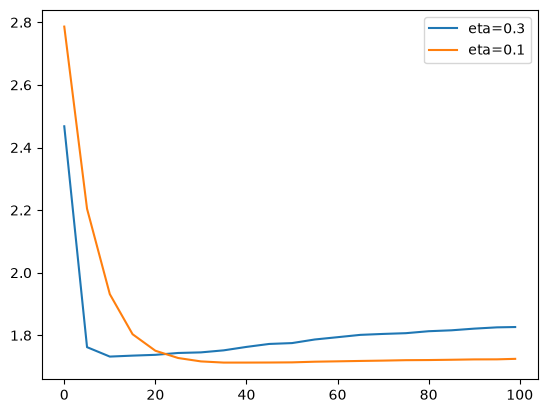

In [69]:
for key, df_rmse in rmses.items():
    plt.plot(df_rmse.num_iter, df_rmse.val_rmse, label=key)

plt.legend()